# Step 1: Load and explore the raw data

**Goal:** look at the raw Online Retail II data *before* changing anything.

Each row is one **product line on an invoice**, not one customer or one order. Keep that in mind: later we will aggregate rows into one row per customer.

The same logic lives in `src/step1_load_explore.py`. This notebook is the step-by-step, run-it-cell-by-cell version.

In [1]:
import sys
from pathlib import Path

import pandas as pd

# Make `src/` importable from the notebooks folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from step1_load_explore import load_raw

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

## 1. Load

The Excel file has two sheets (Dec 2009 - Nov 2010 and Dec 2010 - Dec 2011). `load_raw()` stacks them. The first run reads Excel (~80 s) and caches `data/raw.csv`; later runs take seconds.

In [2]:
df = load_raw()
df.shape

(1067371, 8)

## 2. Columns and types

In [3]:
df.dtypes

Invoice                   str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

In [4]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 3. Missing values

`Customer ID` is missing for about 23% of rows. We can't follow a customer we can't identify.

In [5]:
missing = df.isna().sum().to_frame("missing")
missing["pct"] = (missing["missing"] / len(df) * 100).round(2)
missing

,missing,pct
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


## 4. Date range

About 24 months. This limits how we can split time into a feature window and a target window (step 3).

2009-12-01 07:45:00 -> 2011-12-09 12:50:00


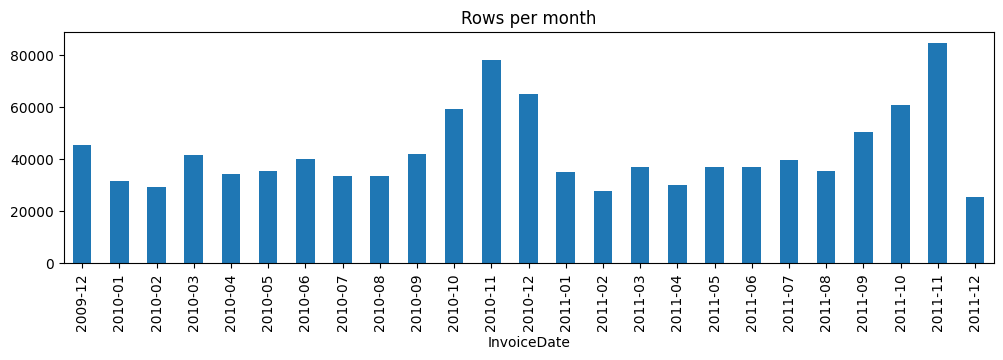

In [6]:
print(df["InvoiceDate"].min(), "->", df["InvoiceDate"].max())
df.groupby(df["InvoiceDate"].dt.to_period("M")).size().plot(kind="bar", figsize=(12, 3), title="Rows per month");

## 5. Numeric summary

Note the minimum and maximum of `Quantity` and `Price`: they are extreme.

In [7]:
df[["Quantity", "Price"]].describe()

,Quantity,Price
count,1.067371e+06,1.067371e+06
mean,9.938898e+00,4.649388e+00
std,1.727058e+02,1.235531e+02
min,-8.099500e+04,-5.359436e+04
25%,1.000000e+00,1.250000e+00
50%,3.000000e+00,2.100000e+00
75%,1.000000e+01,4.150000e+00
max,8.099500e+04,3.897000e+04


## 6. Suspicious rows

These are the things step 2 (cleaning) will have to decide about.

In [8]:
inv = df["Invoice"].astype(str)
summary = pd.Series({
    "Cancelled invoices (start with 'C')": inv.str.startswith("C").sum(),
    "Quantity <= 0": (df["Quantity"] <= 0).sum(),
    "Price <= 0": (df["Price"] <= 0).sum(),
    "No Customer ID": df["Customer ID"].isna().sum(),
}, name="rows").to_frame()
summary["pct"] = (summary["rows"] / len(df) * 100).round(2)
summary

,rows,pct
Cancelled invoices (start with 'C'),19494,1.83
Quantity <= 0,22950,2.15
Price <= 0,6207,0.58
No Customer ID,243007,22.77


In [9]:
print("Unique customers:", df["Customer ID"].nunique())
print("Unique invoices: ", df["Invoice"].nunique())

Unique customers: 5942
Unique invoices:  53628


Look at a few of the odd rows yourself:

In [10]:
print("Most negative prices:")
display(df.nsmallest(3, "Price"))
print("Largest quantities:")
display(df.nlargest(3, "Quantity"))
print("Example cancellations:")
display(df[inv.str.startswith("C")].head(3))

Most negative prices:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom


Largest quantities:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.0,Denmark


Example cancellations:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia


## What we learned

- 1,067,371 rows, 5,942 customers, 53,628 invoices, Dec 2009 to Dec 2011.
- 23% of rows have no Customer ID.
- Cancellations, non-positive quantities/prices and extreme values need a cleaning decision.

**Next (step 2):** decide the cleaning rules. Open question: drop returns entirely, or keep them in a separate table for a later return-rate feature?